# ExoPlex + grid search: determining water content, mantle FeO, and mantle potential temperature

In [1]:
import os
import sys
import io
import contextlib
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

EXOPLEX_DIR = os.path.expanduser("C:/Users/vitor/Downloads/ExoPlex-master/ExoPlex-master")
sys.path.insert(1, EXOPLEX_DIR)
os.chdir(os.path.join(EXOPLEX_DIR, 'Examples'))
os.makedirs('Data', exist_ok=True)

import ExoPlex as exo

FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07

In [2]:
comp_keys = ['wt_frac_water', 'FeMg', 'SiMg', 'CaMg', 'AlMg', 'wt_frac_FeO_wanted',
             'wt_frac_Si_core', 'wt_frac_O_core', 'wt_frac_S_core',
             'combine_phases', 'use_grids', 'conserve_oxy']
struct_keys = ['Pressure_range_mantle_UM', 'Temperature_range_mantle_UM', 'resolution_UM',
               'Pressure_range_mantle_LM', 'Temperature_range_mantle_LM', 'resolution_LM',
               'Mantle_potential_temp', 'water_potential_temp']


def get_planet(mass, water, feo, tpot, femg=FeMg):
    """Roda o ExoPlex e devolve o dicionario `Planet`."""
    n_w = number_h2o_layers if water > 0 else 0          
    layers = [num_mantle_layers, num_core_layers, n_w]   
    comp = dict(zip(comp_keys, [water, femg, SiMg, CaMg, AlMg, feo, wt_frac_Si_core,
                                wt_frac_O_core, wt_frac_S_core, combine_phases,
                                use_grids, conserve_oxy]))
    struct = dict(zip(struct_keys, [Pressure_range_mantle_UM, Temperature_range_mantle_UM,
                                    resolution_UM, Pressure_range_mantle_LM,
                                    Temperature_range_mantle_LM, resolution_LM,
                                    tpot, water_potential_temp]))
    buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(buf):
            filename = exo.functions.find_filename(comp, verbose)
            return exo.run_planet_mass(mass, comp, struct, layers, filename, verbose)
    except SystemExit:
        
        raise RuntimeError(" ".join(buf.getvalue().split()) or "sys.exit() dentro do ExoPlex")


@lru_cache(maxsize=None)                                  
def run_exoplex(mass, water, feo, tpot, femg=FeMg):
    P = get_planet(mass, water, feo, tpot, femg)
    nc = num_core_layers
    return dict(R=P['radius'][-1] / 6371e3,
                M=P['mass'][-1] / 5.97e24,
                CMF=P['mass'][nc] / P['mass'][-1],
                CRF=P['radius'][nc] / P['radius'][-1],
                P_cmb=P['pressure'][nc] / 1e4,            
                T_cmb=P['temperature'][nc])

In [4]:
def plot_structure(Planet, name, water, path=None, subdivide_mantle=True,
                   mantle_bounds_gpa=(120.0, 23.0, 13.5)):
    nc, nm = num_core_layers, num_mantle_layers
    n_w = number_h2o_layers if water > 0 else 0
    r = Planet['radius'] / 1e3
    P = Planet['pressure'] / 1e4
    i_cmb, i_wmb = nc, nc + nm
    r_top = r[i_wmb] if n_w > 0 else r[-1]
    zones = [(0, r[i_cmb], '#555555', 'Core')]
    if subdivide_mantle:
        b1, b2, b3 = mantle_bounds_gpa
        bands = [(np.inf, b1, 'Lower mantle (pPv)', '#9b59b6'),
                 (b1, b2, 'Lower mantle (Bm)', '#c39bd3'),
                 (b2, b3, 'Transition zone', '#d5a56a'),
                 (b3, 0.0, 'Upper mantle', '#ffe14d')]
        P_m, r_m = P[i_cmb:i_wmb + 1][::-1], r[i_cmb:i_wmb + 1][::-1]     
        for p_hi, p_lo, lab, col in bands:
            x0 = r[i_cmb] if np.isinf(p_hi) else float(np.interp(p_hi, P_m, r_m))
            x1 = r_top if p_lo == 0 else float(np.interp(p_lo, P_m, r_m))
            if x1 - x0 > 1.0:                                               
                zones.append((x0, x1, col, lab))
    else:
        zones.append((r[i_cmb], r_top, '#c9a27a', 'Mantle'))
    if n_w > 0:
        zones.append((r[i_wmb], r[-1], '#4aa3df', 'Water / ice'))

    panels = [('Density', Planet['density'], 'Density in $kg/m^3$'),
              ('Pressure', P, 'Pressure in GPa'),
              ('Temperature', Planet['temperature'], 'Temperature in K'),
              ('Gravity', Planet['gravity'], 'Gravitational acceleration in $m/s^2$')]
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True)
    for ax, (title, y, ylabel) in zip(axes.ravel(), panels):
        for x0, x1, c, _ in zones:
            ax.axvspan(x0, x1, color=c, alpha=0.3, lw=0)
        ax.plot(r, y, 'k', lw=1.8)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
    for ax in axes[1]:
        ax.set_xlabel('Radius in km')
    fig.suptitle(f'Planetary Interior Structure of {name}', fontsize=18, fontweight='bold')
    handles = [mpatches.Patch(color=c, alpha=0.4, label=l) for _, _, c, l in zones]
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False)
    plt.tight_layout(rect=[0, 0.04, 1, 0.96])
    if path:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()

In [5]:
EARLY_STOP = 0.0001    
LOCK       = 0.0001   

def grid_search_exoplex(mass, r_obs, water, feo, tpot, femg=FeMg, early_stop=None, lock=None):
    """
    err2 = sqrt(((R-R_obs)/R_obs)^2 + ((M-M_obs)/M_obs)^2)    (igual ao ROWS)
    Lacos: agua (externo) -> FeO -> Tpot.
    early_stop: para no 1o ponto com err2 < early_stop         (= grid_search_rows)
    lock: no 1o ponto com err2 < lock, TRAVA a agua e varre so FeO x Tpot dela (= grid_search_rows2)
    """
    rows, best = [], None
    total = len(water) * len(feo) * len(tpot)
    count, locked_w = 0, None
    for w in water:
        if locked_w is not None and w != locked_w:
            break
        for f in feo:
            for t in tpot:
                count += 1
                try:
                    out = run_exoplex(mass, w, f, t, femg)
                except Exception as e:
                    print(f"[{count}/{total}] agua={w:.4f} FeO={f:.2f} Tpot={t:.0f} -> ERRO: {str(e)[:70]}")
                    continue
                err2 = np.hypot((out['R'] - r_obs) / r_obs, (out['M'] - mass) / mass)
                row = dict(water=w, FeO=f, Tpot=t, err2=err2, **out)
                rows.append(row)
                msg = (f"[{count}/{total}] agua={w:.4f} FeO={f:.2f} Tpot={t:.0f} -> "
                       f"R={out['R']:.4f} R_E, M={out['M']:.4f} M_E, err2={err2:.4f}")
                if best is None or err2 < best['err2']:
                    best = row
                if lock is not None and locked_w is None and err2 < lock:
                    locked_w = w
                    msg += "  agua TRAVADA"
                print(msg)
                if lock is None and early_stop is not None and err2 < early_stop:
                    print(f"err2 = {err2:.5f} < {early_stop} -> otimo ajuste; busca interrompida")
                    return best, pd.DataFrame(rows)
    if lock is not None and locked_w is None and best is not None:
        print(f"AVISO: nenhum ponto abaixo de lock={lock}; melhor err2 = {best['err2']:.4f}")
    print(f"melhores valores: água = {best['water']*100:.2f} wt% | FeO = {best['FeO']*100:.1f} wt% | "
      f"Tpot = {best['Tpot']:.0f} K | err2 = {best['err2']:.4f}")
    return best, pd.DataFrame(rows)


def janela(valor, pct, minimo, maximo, largura_se_zero=None):
    """[valor*(1-pct), valor*(1+pct)] cortado em [minimo, maximo].
    Se valor == 0, começa em 0 e vai até largura_se_zero (valor absoluto)."""
    if valor == 0 and largura_se_zero is not None:
        lo, hi = 0.0, largura_se_zero
    else:
        lo, hi = valor * (1 - pct), valor * (1 + pct)
    return max(lo, minimo), min(hi, maximo)

def refine(best, n=10, pct_agua=0.25, pct_tpot=0.10, agua_max_se_zero=0.005):
    w0, w1 = janela(best['water'], pct_agua, 0.0, 1.0, largura_se_zero=agua_max_se_zero)
    t0, t1 = janela(best['Tpot'], pct_tpot, min(TPOT), max(TPOT))
    water = np.linspace(w0, w1, n).tolist()
    tpot  = np.linspace(t0, t1, n).tolist()
    print(f"\n=== REFINAMENTO === agua {w0*100:.3f}-{w1*100:.3f} wt% (+-{pct_agua*100:.0f}%), "
          f"Tpot {t0:.0f}-{t1:.0f} K (+-{pct_tpot*100:.0f}%), FeO fixo = {best['FeO']} ({n}x{n})")
    return grid_search_exoplex(MASS, RADIUS, water, [best['FeO']], tpot, early_stop=None, lock=LOCK)

# Terra

In [6]:
NAME = 'Terra'
MASS = 1.0            
RADIUS = 1.0          
RADIUS_ERR = 0.001      
T_SURF = 288.0           


FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       # razoes molares (Terra)
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True        
verbose = False

In [7]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]      
                                    
TPOT = [1500, 1600, 1800, 2000]     
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=0.9911 R_E, M=1.0000 M_E, err2=0.0089
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=0.9924 R_E, M=1.0000 M_E, err2=0.0076
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=0.9949 R_E, M=1.0000 M_E, err2=0.0051
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=0.9976 R_E, M=1.0000 M_E, err2=0.0024
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=0.9935 R_E, M=1.0000 M_E, err2=0.0065
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=0.9947 R_E, M=1.0000 M_E, err2=0.0053
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=0.9971 R_E, M=1.0000 M_E, err2=0.0029
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=0.9998 R_E, M=1.0000 M_E, err2=0.0002
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=0.9950 R_E, M=1.0000 M_E, err2=0.0050
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=0.9962 R_E, M=1.0000 M_E, err2=0.0038
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=0.9985 R_E, M=1.0000 M_E, err2=0.0015
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=1.0012 R_E, M=1.0000 M_E, err2=0.0012
[13/224] agua

In [8]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")


=== MELHOR AJUSTE ===
agua = 0.08 wt%   FeO do manto = 0.08   T potencial do manto = 1820 K
R = 0.9999 R_E (obs 1.0 +- 0.001)   M = 1.000 M_E   chi2 = 0.0001
CMF = 0.380   CRF = 0.597   P_CMB = 116.1 GPa   T_CMB = 2826 K



27 de 27 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF     P_cmb      T_cmb
min  0.000  0.00  1500.0  0.9911  0.3404  100.5274  2216.9751
max  0.001  0.12  2000.0  1.0032  0.4536  125.9267  3173.3880


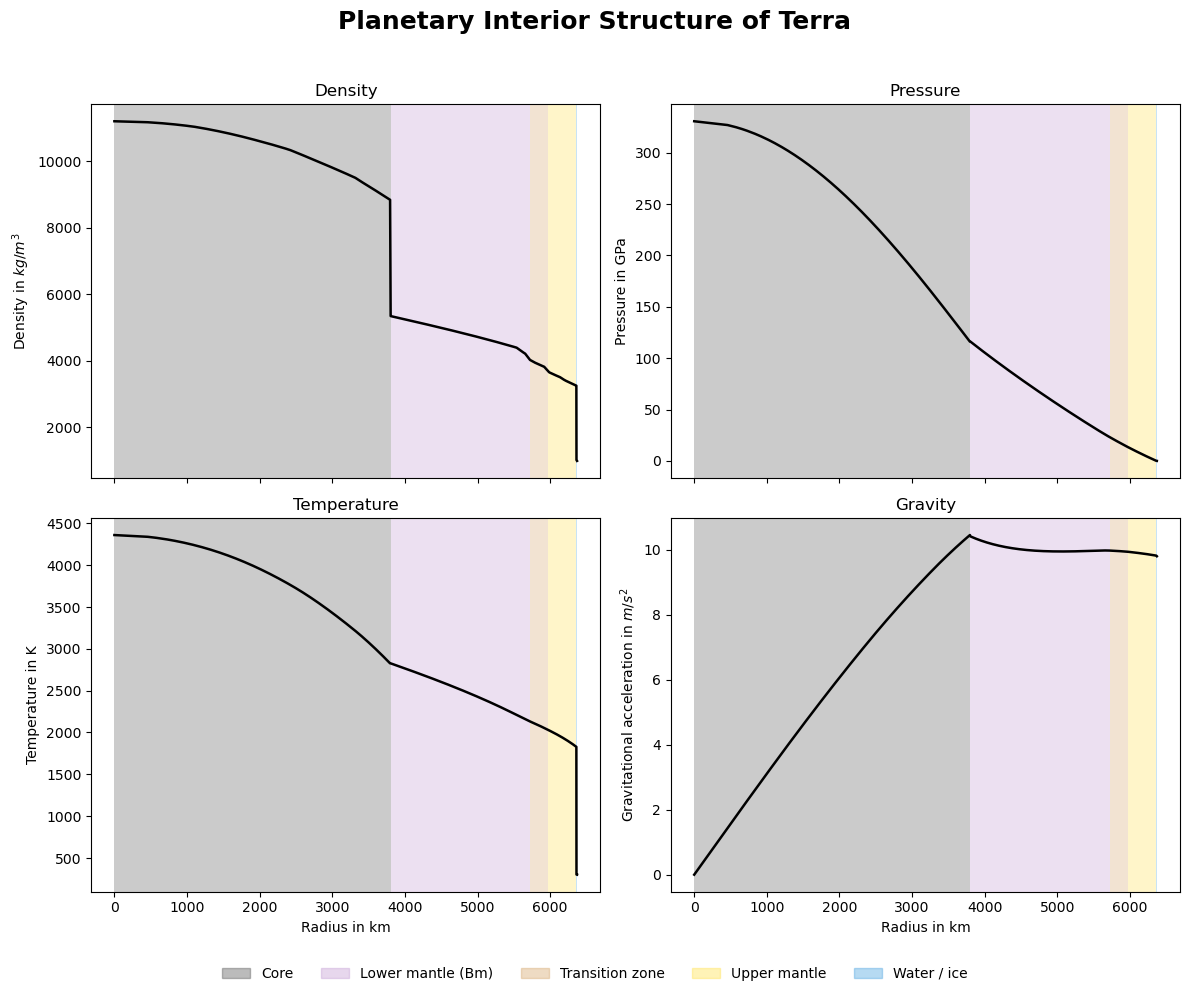

In [9]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:      
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")

# TOI-700 d

In [10]:
NAME = 'TOI-700 D'
MASS = 1.25            
RADIUS = 1.073          
RADIUS_ERR = 0.032      
T_SURF = 308.           

FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True       
verbose = False

In [11]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]       
                                    
TPOT = [1500, 1600, 1800, 2000]     
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=1.0556 R_E, M=1.2500 M_E, err2=0.0162
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=1.0569 R_E, M=1.2500 M_E, err2=0.0150
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=1.0595 R_E, M=1.2500 M_E, err2=0.0126
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=1.0623 R_E, M=1.2500 M_E, err2=0.0100
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=1.0581 R_E, M=1.2500 M_E, err2=0.0139
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=1.0594 R_E, M=1.2500 M_E, err2=0.0127
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=1.0619 R_E, M=1.2500 M_E, err2=0.0103
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=1.0646 R_E, M=1.2500 M_E, err2=0.0078
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=1.0597 R_E, M=1.2500 M_E, err2=0.0124
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=1.0609 R_E, M=1.2500 M_E, err2=0.0112
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=1.0634 R_E, M=1.2500 M_E, err2=0.0089
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=1.0661 R_E, M=1.2500 M_E, err2=0.0064
[13/224] agua

In [12]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")


=== MELHOR AJUSTE ===
agua = 0.81 wt%   FeO do manto = 0.08   T potencial do manto = 1760 K
R = 1.0729 R_E (obs 1.073 +- 0.032)   M = 1.250 M_E   chi2 = 0.0001
CMF = 0.377   CRF = 0.588   P_CMB = 143.7 GPa   T_CMB = 2853 K



58 de 58 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF     P_cmb      T_cmb
min   0.00  0.00  1500.0  1.0556  0.3387  123.4921  2315.7958
max   0.01  0.12  2000.0  1.0765  0.4536  154.9773  3365.9908


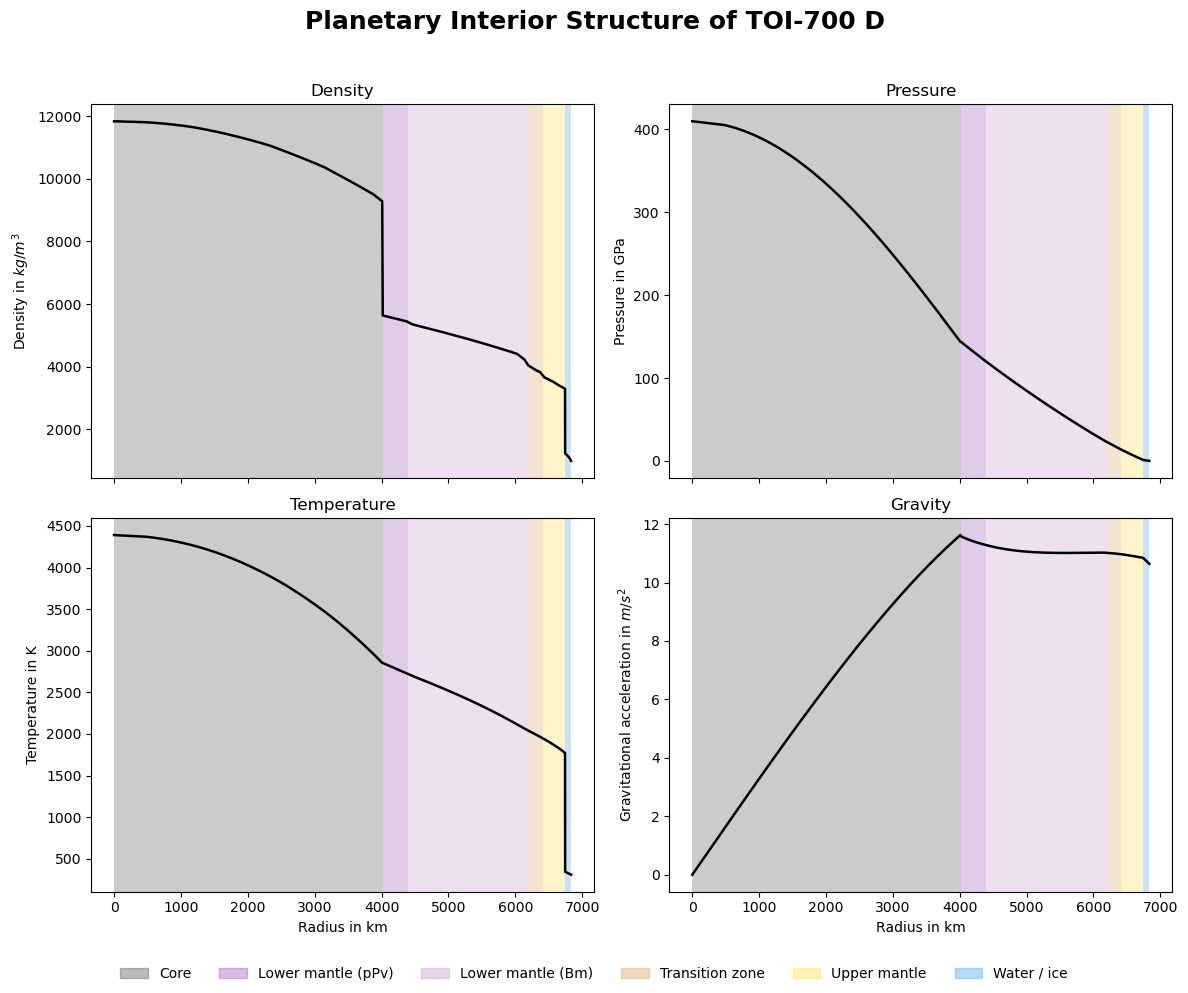

In [13]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")

# TOI-700 e

In [10]:
NAME = 'TOI-700 e'
MASS = 0.818           
RADIUS = 0.953          
RADIUS_ERR = 0.089      
T_SURF = 323.           


FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True        
verbose = False

In [11]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]       
TPOT = [1500, 1600, 1800, 2000]     
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=0.9359 R_E, M=0.8180 M_E, err2=0.0180
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=0.9371 R_E, M=0.8180 M_E, err2=0.0167
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=0.9395 R_E, M=0.8180 M_E, err2=0.0141
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=0.9423 R_E, M=0.8180 M_E, err2=0.0113
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=0.9380 R_E, M=0.8180 M_E, err2=0.0157
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=0.9392 R_E, M=0.8180 M_E, err2=0.0145
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=0.9416 R_E, M=0.8180 M_E, err2=0.0120
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=0.9442 R_E, M=0.8180 M_E, err2=0.0092
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=0.9394 R_E, M=0.8180 M_E, err2=0.0143
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=0.9405 R_E, M=0.8180 M_E, err2=0.0131
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=0.9429 R_E, M=0.8180 M_E, err2=0.0106
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=0.9454 R_E, M=0.8180 M_E, err2=0.0079
[13/224] agua

In [12]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")


=== MELHOR AJUSTE ===
agua = 0.51 wt%   FeO do manto = 0.12   T potencial do manto = 2000 K
R = 0.9531 R_E (obs 0.953 +- 0.089)   M = 0.818 M_E   chi2 = 0.0001
CMF = 0.339   CRF = 0.573   P_CMB = 102.7 GPa   T_CMB = 3043 K



48 de 48 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF     P_cmb      T_cmb
min  0.000  0.00  1500.0  0.9359  0.3387   83.8179  2133.9401
max  0.005  0.12  2000.0  0.9529  0.4536  105.2243  3054.4812


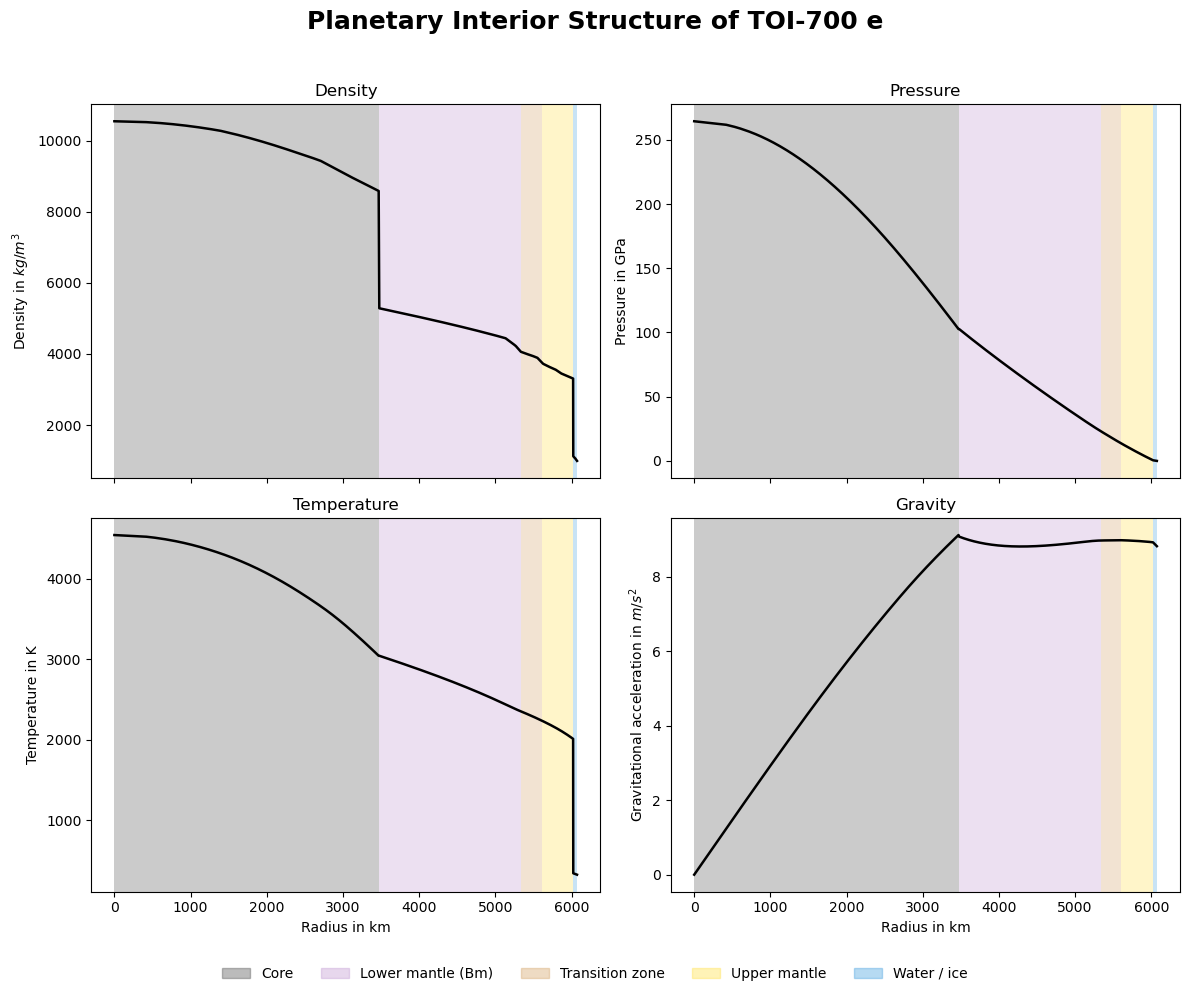

In [13]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")

# Kepler-186 f

In [14]:
NAME = 'Kepler-186 f'
MASS = 1.71           
RADIUS = 1.17          
RADIUS_ERR = 0.08     
T_SURF = 253.          


FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True        
verbose = False

In [15]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]      
                                   
TPOT = [1500, 1600, 1800, 2000]   
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=1.1520 R_E, M=1.7100 M_E, err2=0.0154
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=1.1533 R_E, M=1.7100 M_E, err2=0.0143
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=1.1559 R_E, M=1.7100 M_E, err2=0.0120
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=1.1588 R_E, M=1.7100 M_E, err2=0.0096
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=1.1548 R_E, M=1.7100 M_E, err2=0.0130
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=1.1561 R_E, M=1.7100 M_E, err2=0.0119
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=1.1588 R_E, M=1.7100 M_E, err2=0.0096
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=1.1616 R_E, M=1.7100 M_E, err2=0.0072
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=1.1566 R_E, M=1.7100 M_E, err2=0.0114
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=1.1579 R_E, M=1.7100 M_E, err2=0.0103
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=1.1605 R_E, M=1.7100 M_E, err2=0.0081
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=1.1633 R_E, M=1.7100 M_E, err2=0.0057
[13/224] agua

In [16]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")


=== MELHOR AJUSTE ===
agua = 0.86 wt%   FeO do manto = 0.08   T potencial do manto = 1633 K
R = 1.1700 R_E (obs 1.17 +- 0.08)   M = 1.710 M_E   chi2 = 0.0000
CMF = 0.377   CRF = 0.583   P_CMB = 193.9 GPa   T_CMB = 2846 K



57 de 57 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF     P_cmb      T_cmb
min   0.00  0.00  1500.0  1.1520  0.3387  165.9248  2498.9677
max   0.01  0.12  2000.0  1.1746  0.4536  207.9821  3656.0431


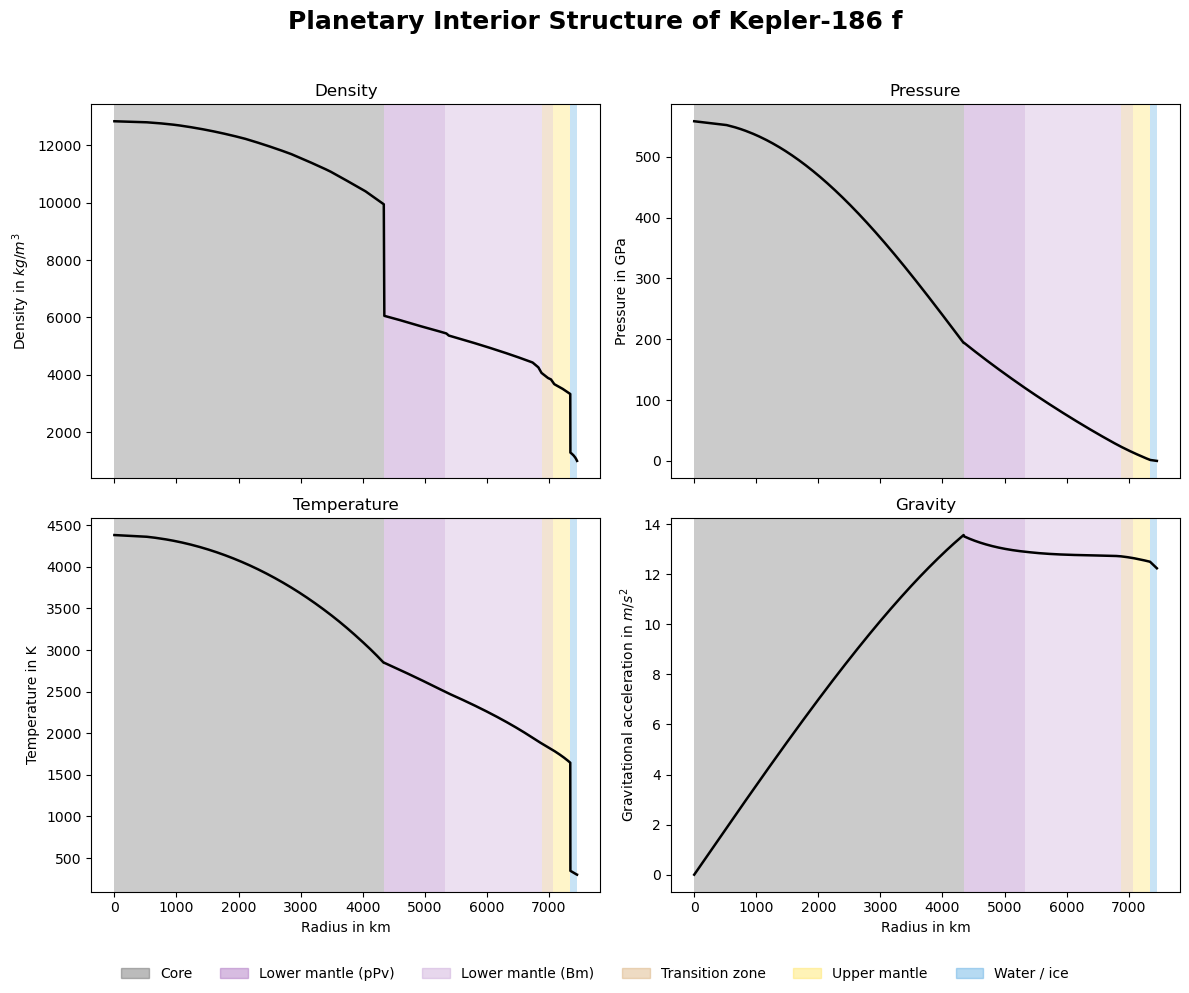

In [17]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")

# LHS-1140 b

In [18]:
NAME = 'LHS-1140 b'
MASS = 5.6            
RADIUS = 1.73          
RADIUS_ERR = 0.025     
T_SURF = 346.           


FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07      
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True        
verbose = False

In [19]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]       
TPOT = [1500, 1600, 1800, 2000]     
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=1.5810 R_E, M=5.6000 M_E, err2=0.0861
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=1.5824 R_E, M=5.6000 M_E, err2=0.0853
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=1.5853 R_E, M=5.6000 M_E, err2=0.0836
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=1.5884 R_E, M=5.6000 M_E, err2=0.0819
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=1.5839 R_E, M=5.6000 M_E, err2=0.0844
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=1.5853 R_E, M=5.6000 M_E, err2=0.0836
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=1.5883 R_E, M=5.6000 M_E, err2=0.0819
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=1.5914 R_E, M=5.6000 M_E, err2=0.0801
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=1.5857 R_E, M=5.6000 M_E, err2=0.0834
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=1.5871 R_E, M=5.6000 M_E, err2=0.0826
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=1.5900 R_E, M=5.6000 M_E, err2=0.0809
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=1.5931 R_E, M=5.6000 M_E, err2=0.0791
[13/224] agua

In [20]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")


=== MELHOR AJUSTE ===
agua = 16.11 wt%   FeO do manto = 0.00   T potencial do manto = 1650 K
R = 1.7273 R_E (obs 1.73 +- 0.025)   M = 5.600 M_E   chi2 = 0.0016
CMF = 0.381   CRF = 0.533   P_CMB = 589.2 GPa   T_CMB = 3250 K



178 de 178 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF     P_cmb      T_cmb
min    0.0  0.00  1500.0  1.5810  0.0340  445.7746  1956.2799
max    0.9  0.12  2000.0  2.1021  0.4536  710.9603  5200.7050


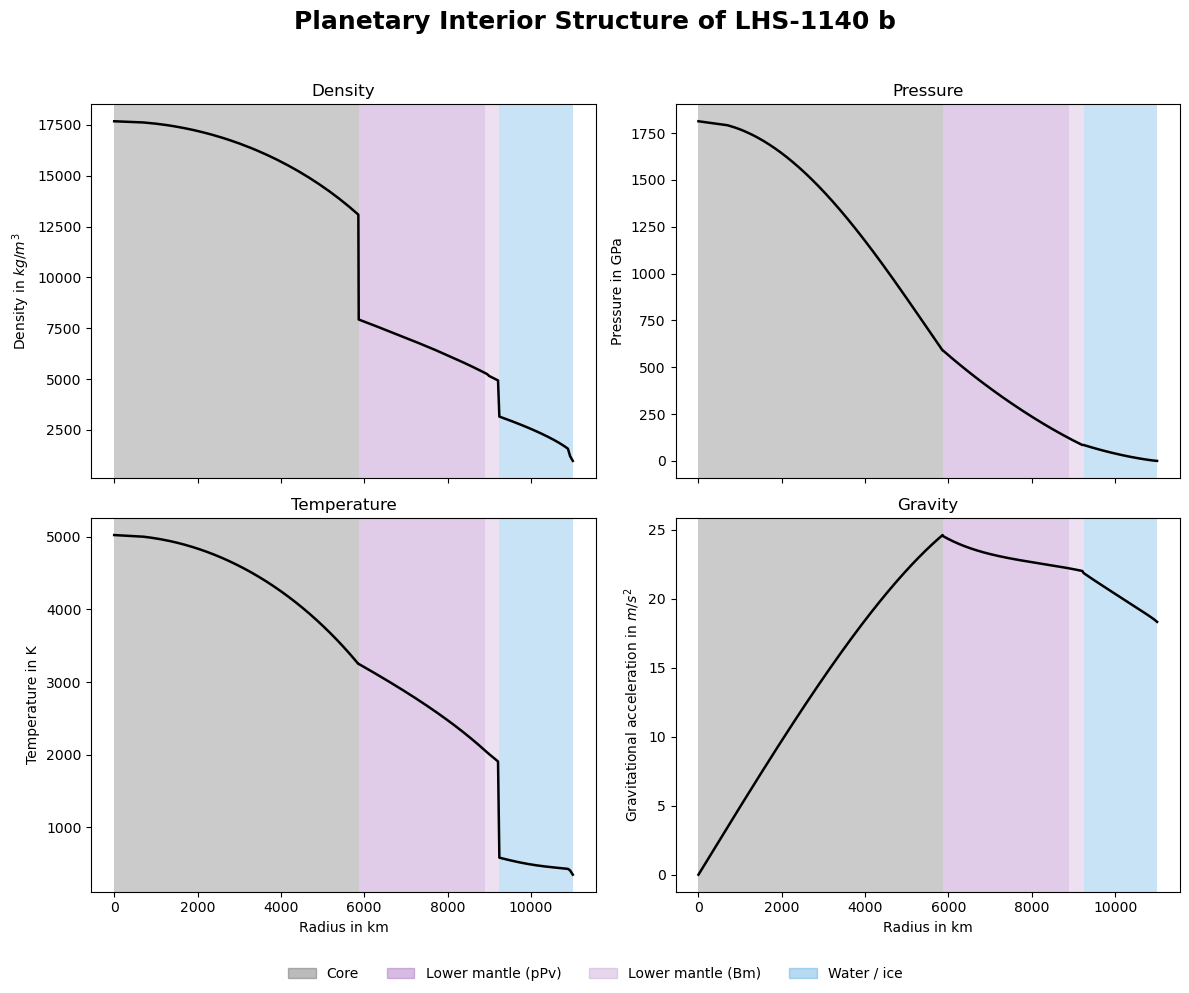

In [21]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")

# K2-18 b

In [22]:
NAME = 'K2-18 b'
MASS = 8.92            
RADIUS = 2.37          
RADIUS_ERR = 0.22      
T_SURF = 317.          


FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07      
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True       
verbose = False




In [23]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]       
TPOT = [1500, 1600, 1800, 2000]     
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=1.7775 R_E, M=8.9200 M_E, err2=0.2500
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=1.7789 R_E, M=8.9200 M_E, err2=0.2494
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=1.7818 R_E, M=8.9200 M_E, err2=0.2482
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=1.7849 R_E, M=8.9200 M_E, err2=0.2469
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=1.7797 R_E, M=8.9200 M_E, err2=0.2491
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=1.7811 R_E, M=8.9200 M_E, err2=0.2485
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=1.7840 R_E, M=8.9200 M_E, err2=0.2472
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=1.7871 R_E, M=8.9200 M_E, err2=0.2459
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=1.7809 R_E, M=8.9200 M_E, err2=0.2486
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=1.7823 R_E, M=8.9200 M_E, err2=0.2480
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=1.7853 R_E, M=8.9200 M_E, err2=0.2467
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=1.7884 R_E, M=8.9200 M_E, err2=0.2454
[13/224] agua

C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:37: RuntimeWarning: invalid value encountered in scalar power
  return 3. * params['K_0'] / 2. * (pow(x, 7. / 3.) - pow(x, 5. / 3.)) \
C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:38: RuntimeWarning: invalid value encountered in scalar power
  * (1. - .75 * (4. - params['Kprime_0']) * (pow(x, 2. / 3.) - 1.)) + params['P_0']


[163/224] agua=0.6000 FeO=0.00 Tpot=1800 -> ERRO: f(a) and f(b) must have different signs


C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:37: RuntimeWarning: invalid value encountered in scalar power
  return 3. * params['K_0'] / 2. * (pow(x, 7. / 3.) - pow(x, 5. / 3.)) \
C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:38: RuntimeWarning: invalid value encountered in scalar power
  * (1. - .75 * (4. - params['Kprime_0']) * (pow(x, 2. / 3.) - 1.)) + params['P_0']


[164/224] agua=0.6000 FeO=0.00 Tpot=2000 -> ERRO: f(a) and f(b) must have different signs
[165/224] agua=0.6000 FeO=0.05 Tpot=1500 -> ERRO: 'pressure'
[166/224] agua=0.6000 FeO=0.05 Tpot=1600 -> ERRO: 'pressure'


...

C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:37: RuntimeWarning: invalid value encountered in scalar power
  return 3. * params['K_0'] / 2. * (pow(x, 7. / 3.) - pow(x, 5. / 3.)) \
C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:38: RuntimeWarning: invalid value encountered in scalar power
  * (1. - .75 * (4. - params['Kprime_0']) * (pow(x, 2. / 3.) - 1.)) + params['P_0']


[98/100] agua=0.6250 FeO=0.12 Tpot=1956 -> ERRO: f(a) and f(b) must have different signs


C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:37: RuntimeWarning: invalid value encountered in scalar power
  return 3. * params['K_0'] / 2. * (pow(x, 7. / 3.) - pow(x, 5. / 3.)) \
C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:38: RuntimeWarning: invalid value encountered in scalar power
  * (1. - .75 * (4. - params['Kprime_0']) * (pow(x, 2. / 3.) - 1.)) + params['P_0']


[99/100] agua=0.6250 FeO=0.12 Tpot=1978 -> ERRO: f(a) and f(b) must have different signs
[100/100] agua=0.6250 FeO=0.12 Tpot=2000 -> ERRO: f(a) and f(b) must have different signs
AVISO: nenhum ponto abaixo de lock=0.0001; melhor err2 = 0.0957
melhores valores: água = 54.17 wt% | FeO = 12.0 wt% | Tpot = 2000 K | err2 = 0.0957


C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:37: RuntimeWarning: invalid value encountered in scalar power
  return 3. * params['K_0'] / 2. * (pow(x, 7. / 3.) - pow(x, 5. / 3.)) \
C:\Users/vitor/Downloads/ExoPlex-master/ExoPlex-master\ExoPlex\burnman\eos\birch_murnaghan.py:38: RuntimeWarning: invalid value encountered in scalar power
  * (1. - .75 * (4. - params['Kprime_0']) * (pow(x, 2. / 3.) - 1.)) + params['P_0']


In [24]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")



=== MELHOR AJUSTE ===
agua = 54.17 wt%   FeO do manto = 0.12   T potencial do manto = 2000 K
R = 2.1432 R_E (obs 2.37 +- 0.22)   M = 8.920 M_E   chi2 = 0.0957
CMF = 0.156   CRF = 0.359   P_CMB = 1127.1 GPa   T_CMB = 2660 K



129 de 129 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF      P_cmb      T_cmb
min    0.0  0.00  1500.0  1.7775  0.1702   881.1666  2365.8374
max    0.5  0.12  2000.0  2.1219  0.4536  1179.7825  6050.1138


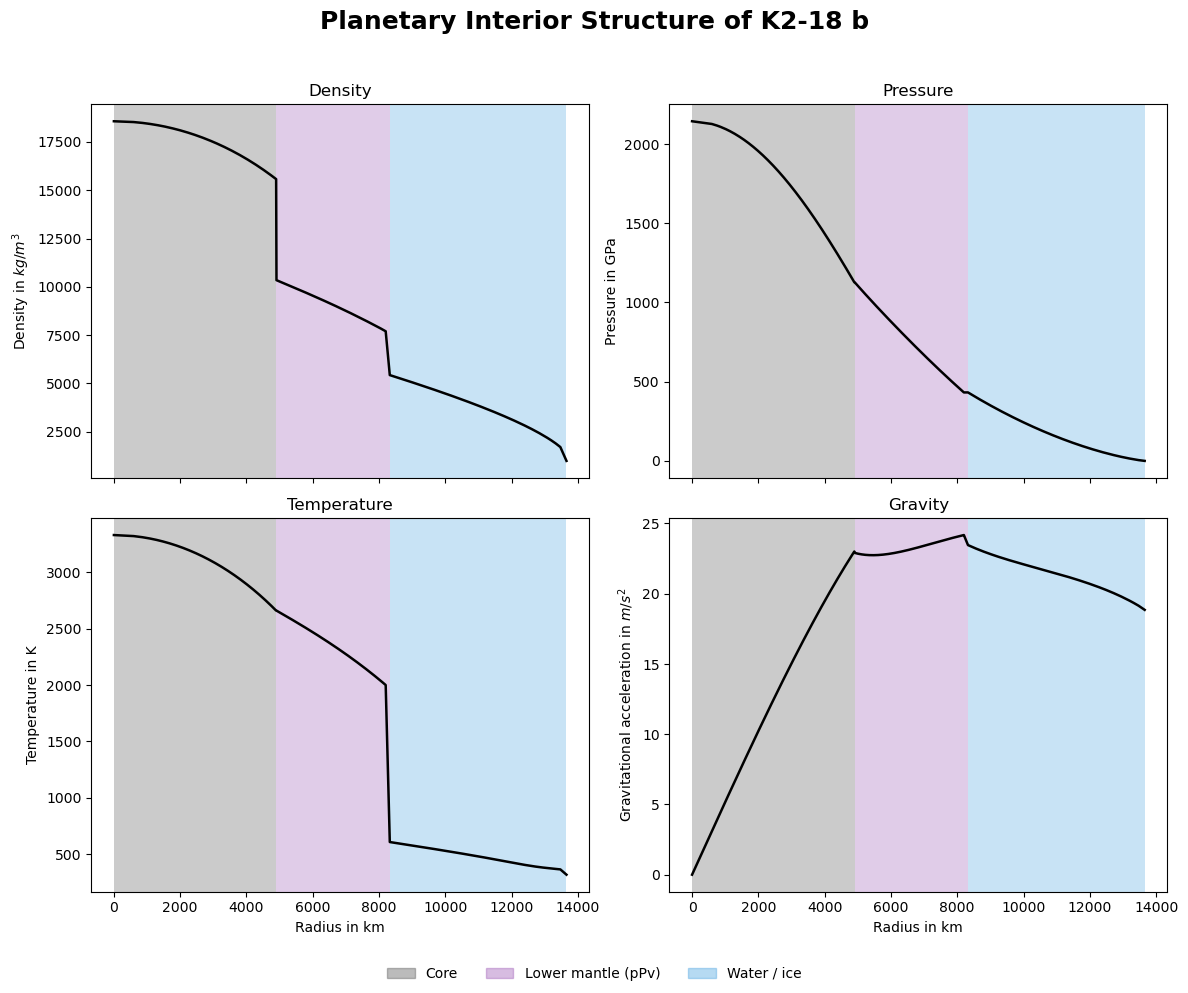

In [25]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:      
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")

# To  Teegarden's Star b

In [26]:
NAME = 'Teegardens Star b'
MASS = 1.16            
RADIUS =1.05          
RADIUS_ERR =  0.2*RADIUS    
T_SURF = 353         


FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07     
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True       
verbose = False



In [27]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]       
TPOT = [1500, 1600, 1800, 2000]     
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=1.0337 R_E, M=1.1600 M_E, err2=0.0155
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=1.0350 R_E, M=1.1600 M_E, err2=0.0143
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=1.0375 R_E, M=1.1600 M_E, err2=0.0119
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=1.0403 R_E, M=1.1600 M_E, err2=0.0093
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=1.0361 R_E, M=1.1600 M_E, err2=0.0132
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=1.0374 R_E, M=1.1600 M_E, err2=0.0120
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=1.0399 R_E, M=1.1600 M_E, err2=0.0097
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=1.0426 R_E, M=1.1600 M_E, err2=0.0071
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=1.0376 R_E, M=1.1600 M_E, err2=0.0118
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=1.0388 R_E, M=1.1600 M_E, err2=0.0106
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=1.0413 R_E, M=1.1600 M_E, err2=0.0083
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=1.0440 R_E, M=1.1600 M_E, err2=0.0057
[13/224] agua

In [28]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")



=== MELHOR AJUSTE ===
agua = 0.43 wt%   FeO do manto = 0.12   T potencial do manto = 1860 K
R = 1.0500 R_E (obs 1.05 +- 0.21000000000000002)   M = 1.160 M_E   chi2 = 0.0000
CMF = 0.339   CRF = 0.568   P_CMB = 142.3 GPa   T_CMB = 3041 K



47 de 47 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF     P_cmb      T_cmb
min  0.000  0.00  1500.0  1.0337  0.3387  115.2007  2285.6265
max  0.005  0.12  2000.0  1.0505  0.4536  144.6340  3302.8285


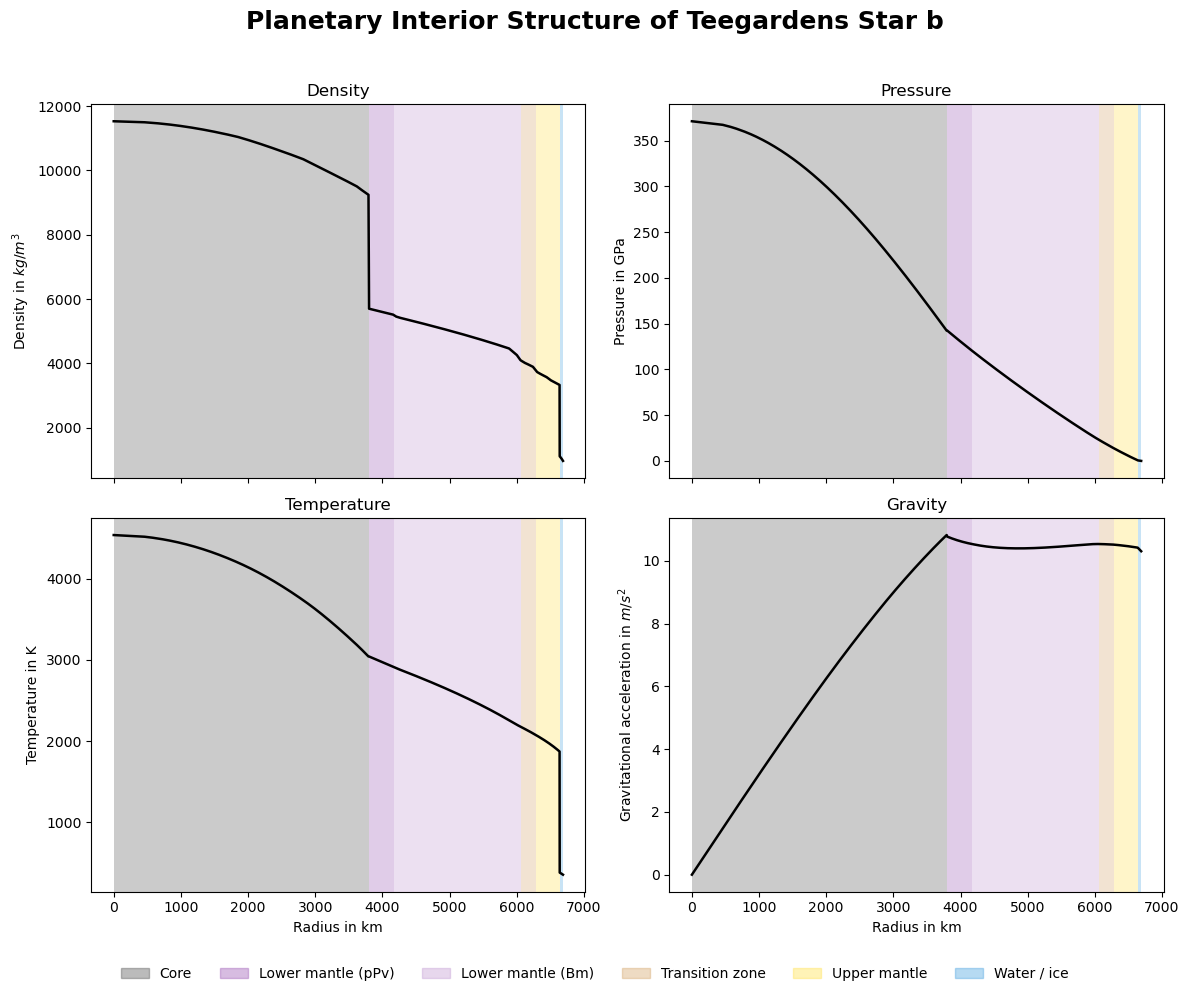

In [29]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:      
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")

#  To  Teegarden's Star c

In [30]:
NAME = 'Teegardens Star c'
MASS = 1.05            
RADIUS = 1.02          
RADIUS_ERR = 0.2*1.02       
T_SURF = 273          

FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True       
verbose = False


In [31]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]       
TPOT = [1500, 1600, 1800, 2000]     
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=1.0050 R_E, M=1.0500 M_E, err2=0.0147
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=1.0062 R_E, M=1.0500 M_E, err2=0.0135
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=1.0087 R_E, M=1.0500 M_E, err2=0.0111
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=1.0115 R_E, M=1.0500 M_E, err2=0.0083
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=1.0074 R_E, M=1.0500 M_E, err2=0.0124
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=1.0086 R_E, M=1.0500 M_E, err2=0.0112
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=1.0110 R_E, M=1.0500 M_E, err2=0.0088
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=1.0137 R_E, M=1.0500 M_E, err2=0.0062
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=1.0088 R_E, M=1.0500 M_E, err2=0.0110
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=1.0100 R_E, M=1.0500 M_E, err2=0.0098
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=1.0124 R_E, M=1.0500 M_E, err2=0.0074
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=1.0151 R_E, M=1.0500 M_E, err2=0.0048
[13/224] agua

In [32]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")



=== MELHOR AJUSTE ===
agua = 0.75 wt%   FeO do manto = 0.00   T potencial do manto = 1980 K
R = 1.0199 R_E (obs 1.02 +- 0.20400000000000001)   M = 1.050 M_E   chi2 = 0.0001
CMF = 0.450   CRF = 0.631   P_CMB = 105.8 GPa   T_CMB = 3007 K



51 de 51 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF     P_cmb      T_cmb
min   0.00  0.00  1500.0  1.0050  0.3387  105.1132  2230.2882
max   0.01  0.12  2000.0  1.0232  0.4536  131.9564  3222.3057


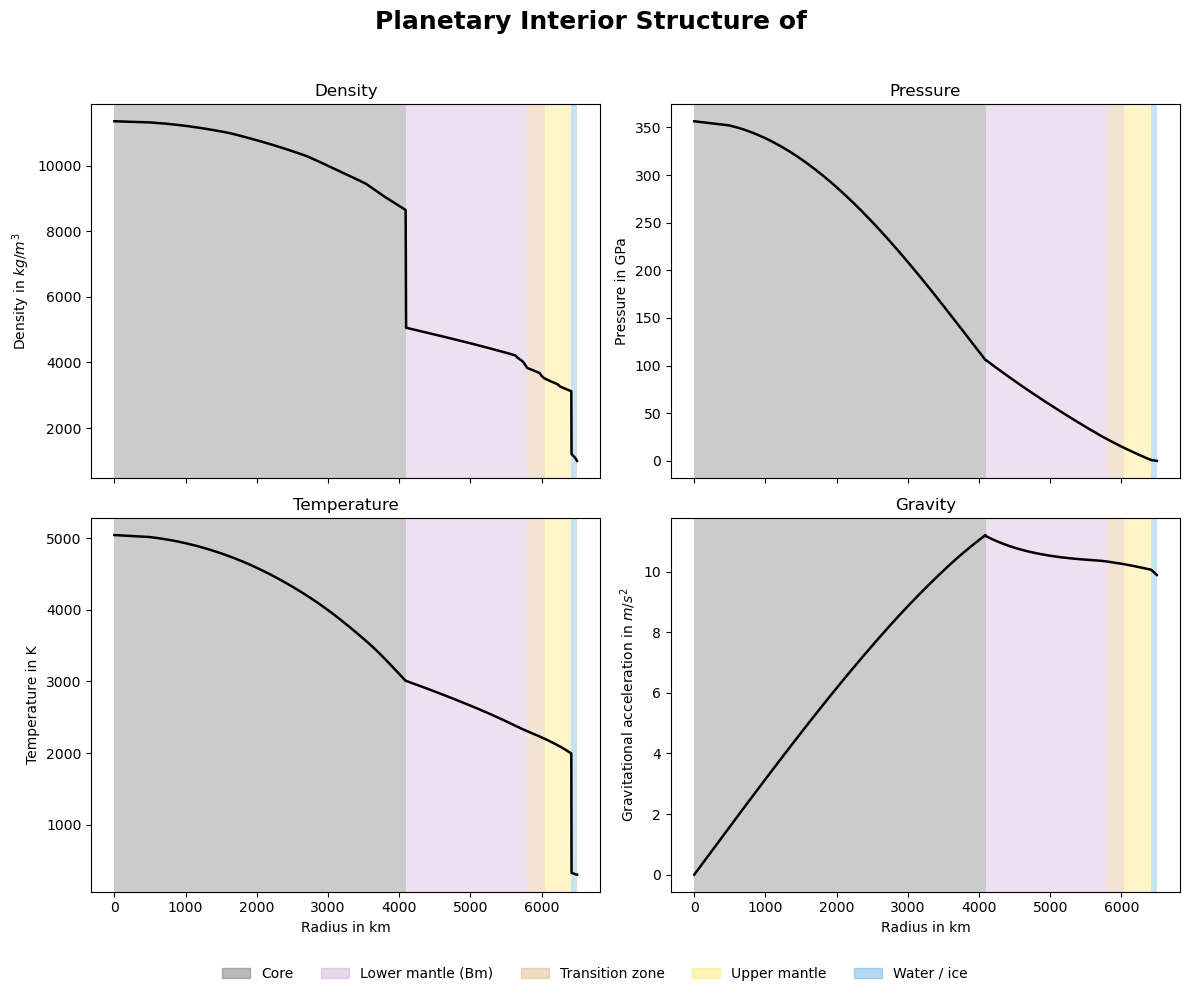

In [33]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:       
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")

# L 98-59 f

In [34]:
NAME = 'L 98-59 f'
MASS =  2.8           
RADIUS =1.48           
RADIUS_ERR = 0.2*RADIUS      
T_SURF = 341          


FeMg, SiMg, AlMg, CaMg = 0.9, 0.9, 0.09, 0.07       
wt_frac_Si_core, wt_frac_O_core, wt_frac_S_core = 0.2, 0., 0.
conserve_oxy = False
number_h2o_layers = 50

water_potential_temp = max(T_SURF, 300.)

Pressure_range_mantle_UM = '1 1400000'
Temperature_range_mantle_UM = '1600 3500'
Pressure_range_mantle_LM = '1250000 40000000'
Temperature_range_mantle_LM = '1700 7000'
resolution_UM = '50 50'
resolution_LM = '20 20'
num_mantle_layers = 500
num_core_layers = 500
combine_phases = True
use_grids = True        
verbose = False

In [35]:
WATER = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FEO = [0.0, 0.05, 0.08, 0.12]       
TPOT = [1500, 1600, 1800, 2000]    
best, table = grid_search_exoplex(MASS, RADIUS, WATER, FEO, TPOT, early_stop=EARLY_STOP)
best, table_ref = refine(best)

[1/224] agua=0.0000 FeO=0.00 Tpot=1500 -> R=1.3179 R_E, M=2.8000 M_E, err2=0.1096
[2/224] agua=0.0000 FeO=0.00 Tpot=1600 -> R=1.3192 R_E, M=2.8000 M_E, err2=0.1087
[3/224] agua=0.0000 FeO=0.00 Tpot=1800 -> R=1.3220 R_E, M=2.8000 M_E, err2=0.1068
[4/224] agua=0.0000 FeO=0.00 Tpot=2000 -> R=1.3250 R_E, M=2.8000 M_E, err2=0.1047
[5/224] agua=0.0000 FeO=0.05 Tpot=1500 -> R=1.3211 R_E, M=2.8000 M_E, err2=0.1074
[6/224] agua=0.0000 FeO=0.05 Tpot=1600 -> R=1.3224 R_E, M=2.8000 M_E, err2=0.1065
[7/224] agua=0.0000 FeO=0.05 Tpot=1800 -> R=1.3252 R_E, M=2.8000 M_E, err2=0.1046
[8/224] agua=0.0000 FeO=0.05 Tpot=2000 -> R=1.3282 R_E, M=2.8000 M_E, err2=0.1026
[9/224] agua=0.0000 FeO=0.08 Tpot=1500 -> R=1.3230 R_E, M=2.8000 M_E, err2=0.1061
[10/224] agua=0.0000 FeO=0.08 Tpot=1600 -> R=1.3244 R_E, M=2.8000 M_E, err2=0.1051
[11/224] agua=0.0000 FeO=0.08 Tpot=1800 -> R=1.3272 R_E, M=2.8000 M_E, err2=0.1032
[12/224] agua=0.0000 FeO=0.08 Tpot=2000 -> R=1.3302 R_E, M=2.8000 M_E, err2=0.1012
[13/224] agua

In [36]:
print("\n=== MELHOR AJUSTE ===")
print(f"agua = {100 * best['water']:.2f} wt%   FeO do manto = {best['FeO']:.2f}   "
      f"T potencial do manto = {best['Tpot']:.0f} K")
print(f"R = {best['R']:.4f} R_E (obs {RADIUS} +- {RADIUS_ERR})   M = {best['M']:.3f} M_E   "
      f"chi2 = {best['err2']:.4f}")
print(f"CMF = {best['CMF']:.3f}   CRF = {best['CRF']:.3f}   "
      f"P_CMB = {best['P_cmb']:.1f} GPa   T_CMB = {best['T_cmb']:.0f} K")



=== MELHOR AJUSTE ===
agua = 20.56 wt%   FeO do manto = 0.12   T potencial do manto = 1956 K
R = 1.4800 R_E (obs 1.48 +- 0.296)   M = 2.800 M_E   chi2 = 0.0000
CMF = 0.270   CRF = 0.468   P_CMB = 344.6 GPa   T_CMB = 3440 K



224 de 224 combinacoes com chi2 < 1 (R dentro de 1 sigma):
     water   FeO    Tpot       R     CMF     P_cmb      T_cmb
min    0.0  0.00  1500.0  1.3179  0.0340  207.5619  1960.6101
max    0.9  0.12  2000.0  1.7888  0.4536  348.7911  4203.1215


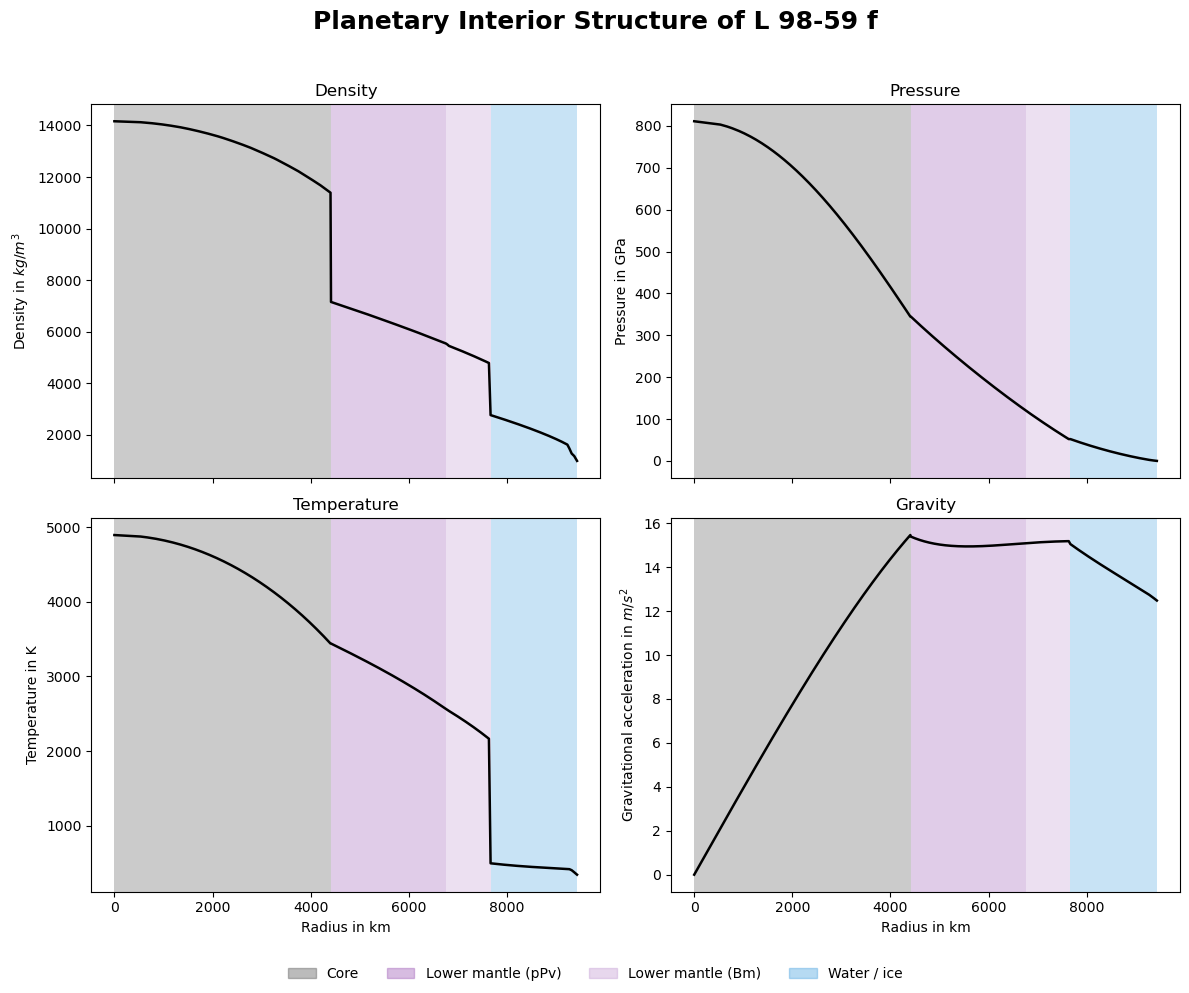

In [37]:
ok = table[table['err2'] < 1.0]
print(f"\n{len(ok)} de {len(table)} combinacoes com chi2 < 1 (R dentro de 1 sigma):")
print(ok[['water', 'FeO', 'Tpot', 'R', 'CMF', 'P_cmb', 'T_cmb']].describe().loc[['min', 'max']].round(4))
table.to_csv(f"Data/{NAME.replace(' ', '_')}_grid.csv", index=False)

Planet = get_planet(MASS, best['water'], best['FeO'], best['Tpot'])
try:
    exo.functions.check(Planet)   
except AssertionError as e:      
    print("AVISO (check do ExoPlex):", e)
plot_structure(Planet, NAME, best['water'], path=f"Data/{NAME.replace(' ', '_')}_structure.png")